In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
#read the data
data=pd.read_csv('student_scores.csv')

In [4]:
#explor the data
data.shape

(25, 2)

In [5]:
data.columns

Index(['Hours', 'Scores'], dtype='object')

In [6]:
data.describe()

,Hours,Scores
count,25.000000,25.000000
mean,5.012000,51.480000
std,2.525094,25.286887
min,1.100000,17.000000
25%,2.700000,30.000000
50%,4.800000,47.000000
75%,7.400000,75.000000
max,9.200000,95.000000


In [7]:
data.dtypes

Hours     float64
Scores      int64
dtype: object

In [8]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Hours,25.0,5.012,2.525094,1.1,2.7,4.8,7.4,9.2
Scores,25.0,51.480,25.286887,17.0,30.0,47.0,75.0,95.0


In [9]:
data.head(10)

,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30
5,1.5,20
6,9.2,88
7,5.5,60
8,8.3,81
9,2.7,25


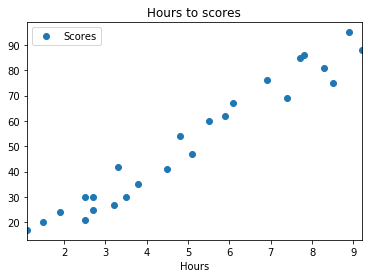

In [11]:
#draw a relationship graph
data.plot(x='Hours',y='Scores',style='o')
plt.title('Hours to scores')
plt.show()

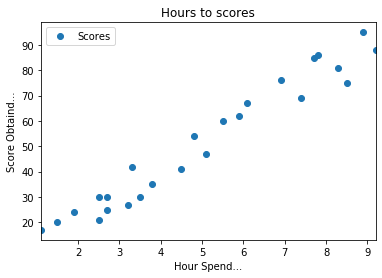

In [14]:
#draw a relationship graph
data.plot(x='Hours',y='Scores',style='o')
plt.xlabel('Hour Spend...')
plt.ylabel('Score Obtaind...')
plt.title('Hours to scores')
plt.show()

In [18]:
X=data.iloc[:,:-1].values

In [19]:
X

array([[2.5],
       [5.1],
       [3.2],
       [8.5],
       [3.5],
       [1.5],
       [9.2],
       [5.5],
       [8.3],
       [2.7],
       [7.7],
       [5.9],
       [4.5],
       [3.3],
       [1.1],
       [8.9],
       [2.5],
       [1.9],
       [6.1],
       [7.4],
       [2.7],
       [4.8],
       [3.8],
       [6.9],
       [7.8]])

In [21]:
Y=data.iloc[:,1].values

In [22]:
Y

array([21, 47, 27, 75, 30, 20, 88, 60, 81, 25, 85, 62, 41, 42, 17, 95, 30,
       24, 67, 69, 30, 54, 35, 76, 86], dtype=int64)

In [23]:
#
from sklearn.model_selection import train_test_split

In [24]:
X_train, X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2, random_state=0)

In [25]:

X_train

array([[3.8],
       [1.9],
       [7.8],
       [6.9],
       [1.1],
       [5.1],
       [7.7],
       [3.3],
       [8.3],
       [9.2],
       [6.1],
       [3.5],
       [2.7],
       [5.5],
       [2.7],
       [8.5],
       [2.5],
       [4.8],
       [8.9],
       [4.5]])

In [26]:
X_train.shape

(20, 1)

In [27]:
from sklearn.linear_model import LinearRegression

In [29]:
#create an instance of the Linear Regression Python object
lmodel=LinearRegression()


In [30]:
lmodel.fit(X_train, Y_train)

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None, normalize=False)

In [32]:
lmodel.intercept_

2.018160041434683

In [34]:
lmodel.coef_

array([9.91065648])

In [35]:
Y_predict=lmodel.predict(X_test)

In [36]:
Y_predict

array([16.88414476, 33.73226078, 75.357018  , 26.79480124, 60.49103328])

In [37]:
Y_test

array([20, 27, 69, 30, 62], dtype=int64)

In [39]:
new_data=pd.DataFrame({'Actual':Y_test, 'Predicted':Y_predict})

In [40]:
new_data

,Actual,Predicted
0,20,16.884145
1,27,33.732261
2,69,75.357018
3,30,26.794801
4,62,60.491033


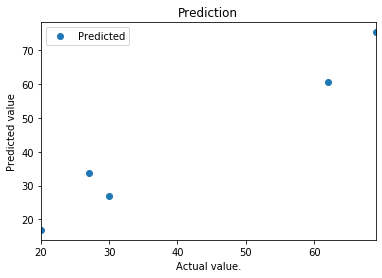

In [42]:
new_data.plot(x='Actual',y='Predicted',style='o')
plt.xlabel('Actual value.')
plt.ylabel('Predicted value')
plt.title('Prediction')
plt.show()

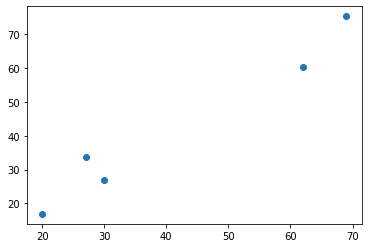

In [45]:
plt.scatter(Y_test,Y_predict)
plt.show()

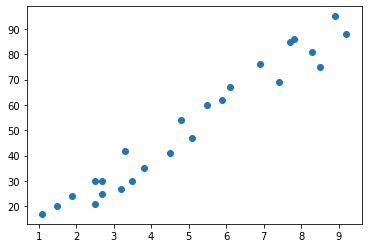

In [52]:
plt.scatter(data['Hours'],data['Scores'])

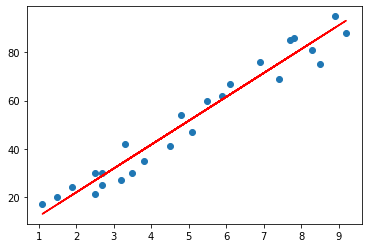

In [59]:
plt.scatter(data['Hours'],data['Scores'])
y=lmodel.intercept_+data['Hours']*lmodel.coef_
plt.plot(data['Hours'],y, color='red')
plt.show()

In [57]:
data['Hours']

0     2.5
1     5.1
2     3.2
3     8.5
4     3.5
5     1.5
6     9.2
7     5.5
8     8.3
9     2.7
10    7.7
11    5.9
12    4.5
13    3.3
14    1.1
15    8.9
16    2.5
17    1.9
18    6.1
19    7.4
20    2.7
21    4.8
22    3.8
23    6.9
24    7.8
Name: Hours, dtype: float64

In [63]:
#Evaluate the model

In [64]:
from sklearn import metrics

In [66]:
metrics.mean_absolute_error(Y_test,Y_predict)

4.183859899002975

In [68]:
metrics.mean_squared_error(Y_test,Y_predict)

21.5987693072174

In [69]:
np.sqrt(metrics.mean_squared_error(Y_test,Y_predict))

4.6474476121003665